In [2]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import duecker_ET_model, simulate_dipole, MPIBackend

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
import sys
import os.path as op
pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
# import pandas as pd
from scipy import signal

from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = 'truetype'

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/beta_events'
os.makedirs(pathfig, exist_ok=True)
import matplotlib
from cmcrameri import cm

step_cm = int(len(cm.lipari.colors) / 7)
cm_time = cm.lipari.colors[len(cm.lipari.colors)-20: 0 : -int(step_cm/1.1)]
cm_time_map = matplotlib.colors.ListedColormap(cm_time)
len(cm_time)
n_procs=10

reduce_percentage = 0.6 # percentage of calcium channels remaining after blocking

In [3]:
mu = 250
tstop = 500

In [4]:
window_len, scaling_factor = 5, 60
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
jit_pos = np.concatenate((np.random.randint(-15,15,(100,2)), np.random.randint(-100,100,(100,1))), axis=1)

for i, pos in enumerate(jit_pos):
    net.pos_dict['L5_pyramidal'][i] = (net.pos_dict['L5_pyramidal'][i][0] + pos[0], net.pos_dict['L5_pyramidal'][i][1] + pos[1], net.pos_dict['L5_pyramidal'][i][2] + pos[2])

depths = list(list(range(0,2200,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)

weights_ampa_p1 = {'L2_basket': 0.01, 'L2_pyramidal': 0.01,
                   'L5_basket': 0.05, 'L5_pyramidal': 0.5}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

ampl = 3
t0 = 200

net.add_evoked_drive(
    'evprox1', mu=mu, sigma=2, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


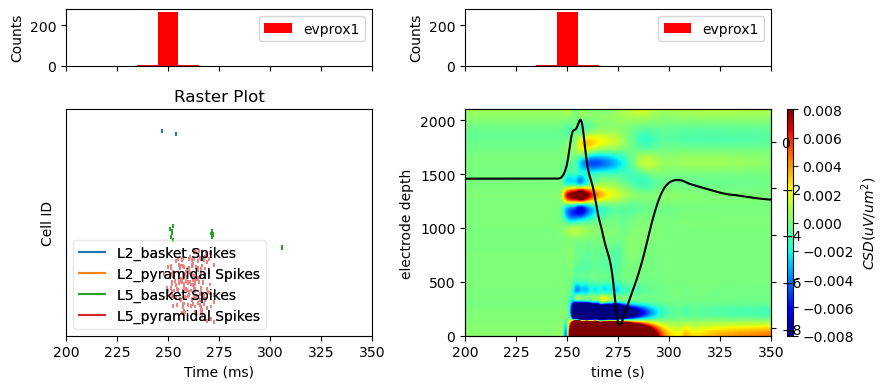

In [17]:
fig, ax = plt.subplots(2,2, figsize=(9,4), height_ratios=[0.25,1], constrained_layout=True, sharex=True)
net.cell_response.plot_spikes_hist(ax=ax[0, 0], show=False)
net.cell_response.plot_spikes_hist(ax=ax[0, 1], show=False)
net.cell_response.plot_spikes_raster(ax=ax[1, 0], show=False)
net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=ax[1,1], show=False, vmin=-0.008, vmax=0.008, sink='b')
ax2tw = ax[1,1].twinx()
ax2tw.plot(dpl[0].times, dpl[0].data['agg'], color='k')
ax[1,1].set_xlim([200, 350])
fig.savefig(op.join(pathfig, 'beta_proximal_544.pdf'))
fig.savefig(op.join(pathfig, 'beta_proximal_544.png'), dpi=300)


In [6]:
def net_block_ca(net_no_ca, perc=0.0):
    # block Ca
    # 
    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] *= perc
    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] *= perc

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        for i in range(len(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])):
            net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1][i] *= perc
            net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1][i] *= perc

    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] *= perc
    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] *= perc

    return net_no_ca

In [7]:
net_no_ca = duecker_ET_model()
net_no_ca = net_block_ca(net_no_ca, perc=0)
net_no_ca.set_cell_positions(inplane_distance=30.)

net_no_ca.add_evoked_drive(
    'evprox1', mu=mu, sigma=1, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl_no_ca = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1,record_ca='all', bsl_cor='calcium')
dpl_no_ca[0].smooth(window_len).scale(scaling_factor)

net_60perc_ca = duecker_ET_model()
net_60perc_ca = net_block_ca(net_60perc_ca, perc=reduce_percentage)
net_60perc_ca.set_cell_positions(inplane_distance=30.)

net_60perc_ca.add_evoked_drive(
    'evprox1', mu=mu, sigma=1, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl_60perc_ca = simulate_dipole(net_60perc_ca, tstop=tstop, n_trials=1,record_ca='all', bsl_cor='calcium')
dpl_60perc_ca[0].smooth(window_len).scale(scaling_factor)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

In [8]:
l5_ca_tuft = np.zeros((100, len(net.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net.gid_ranges['L5_pyramidal']):
    l5_ca_tuft[g] = net.cell_response.ca[0][gid]['apical_tuft']

l5_ca_tuft_60perc = np.zeros((100, len(net_60perc_ca.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net_60perc_ca.gid_ranges['L5_pyramidal']):
    l5_ca_tuft_60perc[g] = net_60perc_ca.cell_response.ca[0][gid]['apical_tuft']

l5_ca_tuft_noca = np.zeros((100, len(net_no_ca.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net_no_ca.gid_ranges['L5_pyramidal']):
    l5_ca_tuft_noca[g] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']

In [9]:
from scipy.signal import find_peaks
peaks, _ = find_peaks(-dpl[0].data['L5'], height=50)

In [10]:
bins = np.arange(0, tstop, 10)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)


In [44]:
from hnn_core.viz import _get_plot_data_trange
from mne.time_frequency import tfr_array_morlet

In [45]:
data, times = _get_plot_data_trange(dpl[0].times, dpl[0].data['agg'])
data = np.r_[data[-1:0:-1], data, data[-2::-1]]

# MNE expects an array of shape (n_trials, n_channels, n_times)
data = data[None, None, :]
freqs = np.arange(6, 50, 1)

power = tfr_array_morlet(data, sfreq=dpl[0].sfreq, freqs=freqs,
                            n_cycles=3, output='power')

power = power[:, :, :, times.shape[0] - 1:2 * times.shape[0] - 1]
power.shape

(1, 1, 44, 20000)

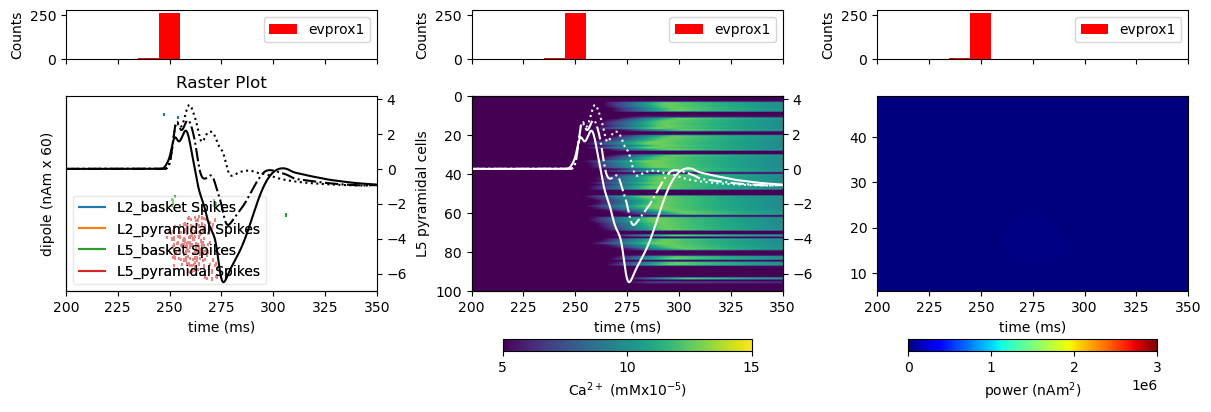

In [ ]:
# fig, ax = plt.subplots(2, 3, figsize=(12, 4), constrained_layout=True, height_ratios=[0.25, 1], sharex=True)
# net.cell_response.plot_spikes_hist(ax=ax[0, 0], show=False)
# net.cell_response.plot_spikes_hist(ax=ax[0, 1], show=False)
# net.cell_response.plot_spikes_hist(ax=ax[0, 2], show=False)

# net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)

# axtw10 = ax[1, 0].twinx()
# axtw10.plot(dpl[0].times, dpl[0].data['agg'], color='k', label='calcium')
# axtw10.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='k', linestyle=':', label='block calcium')
# axtw10.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='k', linestyle='-.', label='block calcium')

# ax[1, 0].set_ylabel('dipole (nAm x {scaling_factor})'.format(scaling_factor=scaling_factor))

# ax[1, 0].spines['top'].set_visible(False)
# ax[1, 0].spines['right'].set_visible(False)

# im = ax[1, 1].imshow(l5_ca_tuft, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
# ax[1, 1].set_ylabel('L5 pyramidal cells')
# cb = plt.colorbar(im, ax=ax[1,1],  shrink=0.8, orientation='horizontal', pad=0.02)
# cb.ax.set_xlabel('Ca$^{2+}$ (mMx10$^{-5}$)')
# cb.set_ticks([5e-5, 10e-5, 15e-5])
# cb.ax.set_xticklabels(['5', '10', '15'])

# axtw11 = ax[1, 1].twinx()
# axtw11.plot(dpl[0].times, dpl[0].data['agg'], color='w', label='calcium')
# axtw11.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='w',label='block calcium', linestyle=':')
# axtw11.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='w',label='calcium 60 percent', linestyle='-.')

# im = ax[1,2].imshow(power[0, 0, :, :], aspect='auto', cmap='jet', extent=[dpl[0].times[0], dpl[0].times[-1], freqs[0], freqs[-1]], origin='lower', rasterized=True, vmin=0, vmax=3e6)
# cb = plt.colorbar(im, ax=ax[1,2],  shrink=0.8, orientation='horizontal', pad=0.02)
# cb.ax.set_xlabel(r'power (nAm$^2$)')
# # cb.set_ticks([5e-5, 10e-5, 15e-5])
# # cb.ax.set_xticklabels(['5', '10', '15'])
# for i in range(3):
#     ax[1, i].set_xlabel('time (ms)')
#     ax[1, 0].set_xlim([200, 350])


# fig.savefig(os.path.join(pathfig, 'duecker_2025_ET_beta_reduce_ca_soma.pdf'), dpi=300) 

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_58081/2369073023.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cb.ax.set_xticklabels([0, 5, 10, 15])


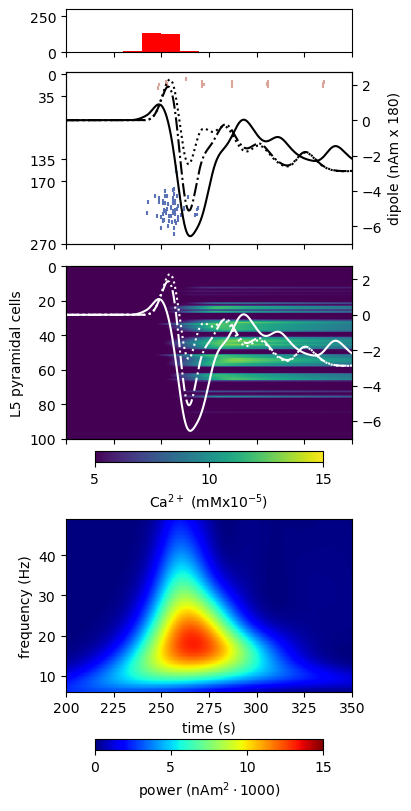

In [83]:
fig, ax = plt.subplots(4,1, figsize=(4,8), constrained_layout=True, sharex=True, height_ratios=[0.25, 1, 1, 1])

ax[0].hist(spike_prox1, bins, color='r')
ax[0].set_ylim([0, 300])


I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 

colors = [assign_color(net, gid) for gid in gids]

ax[1].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1].invert_yaxis()
ax[1].set_yticks([0, 35, 135, 170, 270])
axtw10 = ax[1].twinx()
axtw10.plot(dpl[0].times, dpl[0].data['agg'], color='k', label='calcium')
axtw10.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='k', linestyle=':', label='block calcium')
axtw10.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='k', linestyle='-.', label='block calcium')

axtw10.set_ylabel('dipole (nAm x {scaling_factor})'.format(scaling_factor=scaling_factor))

ax[1].set_xlim([400, 650])

im = ax[2].imshow(l5_ca_tuft, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
ax[2].set_ylabel('L5 pyramidal cells')
cb = plt.colorbar(im, ax=ax[2],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel('Ca$^{2+}$ (mMx10$^{-5}$)')
cb.set_ticks([5e-5, 10e-5, 15e-5])
cb.ax.set_xticklabels(['5', '10', '15'])

axtw11 = ax[2].twinx()
axtw11.plot(dpl[0].times, dpl[0].data['agg'], color='w', label='calcium')
axtw11.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='w',label='block calcium', linestyle=':')
axtw11.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='w',label='calcium 60 percent', linestyle='-.')

im = ax[3].imshow(power[0, 0, :, :], aspect='auto', cmap='jet', extent=[dpl[0].times[0], dpl[0].times[-1], freqs[0], freqs[-1]], origin='lower', rasterized=True, vmin=0, vmax=15e3)
ax[3].set_ylabel('frequency (Hz)')
cb = plt.colorbar(im, ax=ax[3],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel(r'power (nAm$^2 \cdot 1000$)')
cb.ax.set_xticklabels([0, 5, 10, 15])
ax[3].set_xlabel('time (s)')
ax[3].set_xlim([200, 350])
ax[3].set_xticks(np.arange(200, 351, 25))

fig.savefig(os.path.join(pathfig, 'proximal_beta_column.pdf'), dpi=300) 

NameError: name 'net_60perc_ca' is not defined

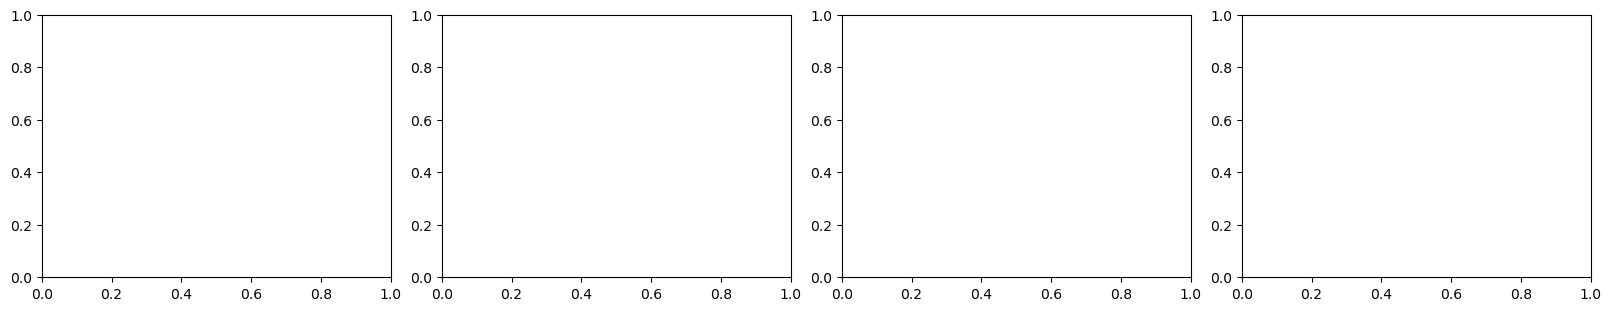

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3), constrained_layout=True, sharex=True)
net_60perc_ca.cell_response.plot_spikes_raster(ax=ax[0], show=False)
im = ax[1].imshow(l5_ca_tuft_60perc, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
ax[1].set_ylabel('L5 pyramidal cells')

net_no_ca.cell_response.plot_spikes_raster(ax=ax[2], show=False)
im = ax[3].imshow(l5_ca_tuft_noca, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)


for i in range(4):
    ax[i].set_xlabel('time (s)')
    ax[i].set_xlim([200, 350])
    ax[i].set_xticks(np.arange(200, 351, 25))
    
ax[3].set_ylabel('L5 pyramidal cells')
fig.savefig(os.path.join(pathfig, 'duecker_2025_ET_beta_reduce_ca_spike_change.pdf'), dpi=300) 

In [18]:
window_len, scaling_factor = 15, 180
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(0,2200,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_basket': 0.0001, 'L2_pyramidal': 0.01,
                   'L5_basket': 0.0001, 'L5_pyramidal': 0.1}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}
weights_ampa_d = {'L2_basket': 0.001, 'L2_pyramidal': 0.01,
                   'L5_pyramidal': 0.1}
weights_nmda_d = {'L2_basket': 0.035, 'L2_pyramidal': 0.01,
                   'L5_pyramidal': 0.01}
synaptic_delays_dist = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_pyramidal': 1.}
ampl = 3
t0 = 200

net.add_evoked_drive(
    'evprox1', mu=mu, sigma=5, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)
net.add_evoked_drive(
    'evdist', mu=mu, sigma=1.5, numspikes=1, weights_ampa=weights_ampa_d,
    weights_nmda=weights_nmda_d, location='distal',
    synaptic_delays=synaptic_delays_dist, event_seed=255)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=tstop, n_trials=1,record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)


net_no_ca = duecker_ET_model()
net_no_ca = net_block_ca(net_no_ca, perc=0)
net_no_ca.set_cell_positions(inplane_distance=30.)

net_no_ca.add_evoked_drive(
    'evprox1', mu=mu, sigma=2, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)

net_no_ca.add_evoked_drive(
    'evdist', mu=mu, sigma=1, numspikes=1, weights_ampa=weights_ampa_d,
    weights_nmda=weights_nmda_d, location='distal',
    synaptic_delays=synaptic_delays_dist, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl_no_ca = simulate_dipole(net_no_ca, tstop=tstop, n_trials=1,record_ca='all', bsl_cor='calcium')
dpl_no_ca[0].smooth(window_len).scale(scaling_factor)

net_60perc_ca = duecker_ET_model()
net_60perc_ca = net_block_ca(net_60perc_ca, perc=reduce_percentage)
net_60perc_ca.set_cell_positions(inplane_distance=30.)

net_60perc_ca.add_evoked_drive(
    'evprox1', mu=mu, sigma=2, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)

net_60perc_ca.add_evoked_drive(
    'evdist', mu=mu, sigma=1, numspikes=1, weights_ampa=weights_ampa_d,
    weights_nmda=weights_nmda_d, location='distal',
    synaptic_delays=synaptic_delays_dist, event_seed=544)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl_60perc_ca = simulate_dipole(net_60perc_ca, tstop=tstop, n_trials=1,record_ca='all', bsl_cor='calcium')
dpl_60perc_ca[0].smooth(window_len).scale(scaling_factor)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files

In [73]:
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


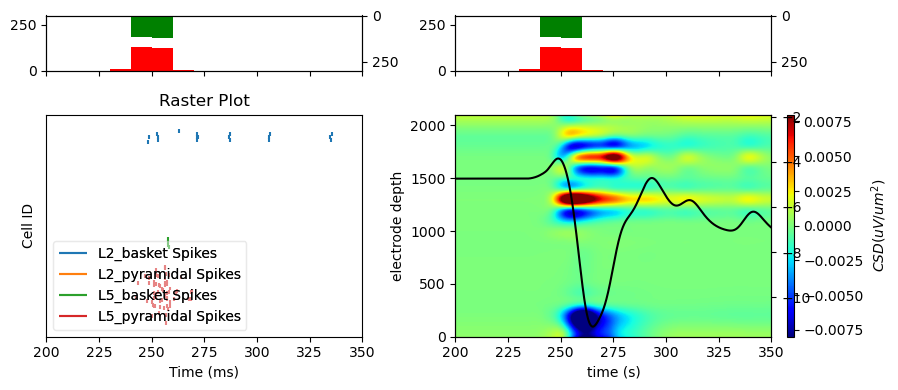

In [20]:
fig, ax = plt.subplots(2,2, figsize=(9,4), height_ratios=[0.25,1], constrained_layout=True, sharex=True)
# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

for i in range(2):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 300])

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 300])
    ax1tw.invert_yaxis()
net.cell_response.plot_spikes_raster(ax=ax[1, 0], show=False)
net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=ax[1,1], show=False, vmin=-0.008, vmax=0.008, sink='b')
ax2tw = ax[1,1].twinx()
ax2tw.plot(dpl[0].times, dpl[0].data['agg'], color='k')
ax[1,1].set_xlim([200, 350])
fig.savefig(op.join(pathfig, 'beta_coincidence_544.pdf'))
fig.savefig(op.join(pathfig, 'beta_coincidence_544.png'), dpi=300)

In [74]:
data, times = _get_plot_data_trange(dpl[0].times, dpl[0].data['agg'])
data = np.r_[data[-1:0:-1], data, data[-2::-1]]

# MNE expects an array of shape (n_trials, n_channels, n_times)
data = data[None, None, :]
freqs = np.arange(6, 50, 1)

power = tfr_array_morlet(data, sfreq=dpl[0].sfreq, freqs=freqs,
                            n_cycles=3, output='power')

power = power[:, :, :, times.shape[0] - 1:2 * times.shape[0] - 1]
power.shape

l5_ca_tuft = np.zeros((100, len(net.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net.gid_ranges['L5_pyramidal']):
    l5_ca_tuft[g] = net.cell_response.ca[0][gid]['apical_tuft']

l5_ca_tuft_60perc = np.zeros((100, len(net_60perc_ca.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net_60perc_ca.gid_ranges['L5_pyramidal']):
    l5_ca_tuft_60perc[g] = net_60perc_ca.cell_response.ca[0][gid]['apical_tuft']

l5_ca_tuft_noca = np.zeros((100, len(net_no_ca.cell_response.ca[0][170]['soma'])))
for g, gid in enumerate(net_no_ca.gid_ranges['L5_pyramidal']):
    l5_ca_tuft_noca[g] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']

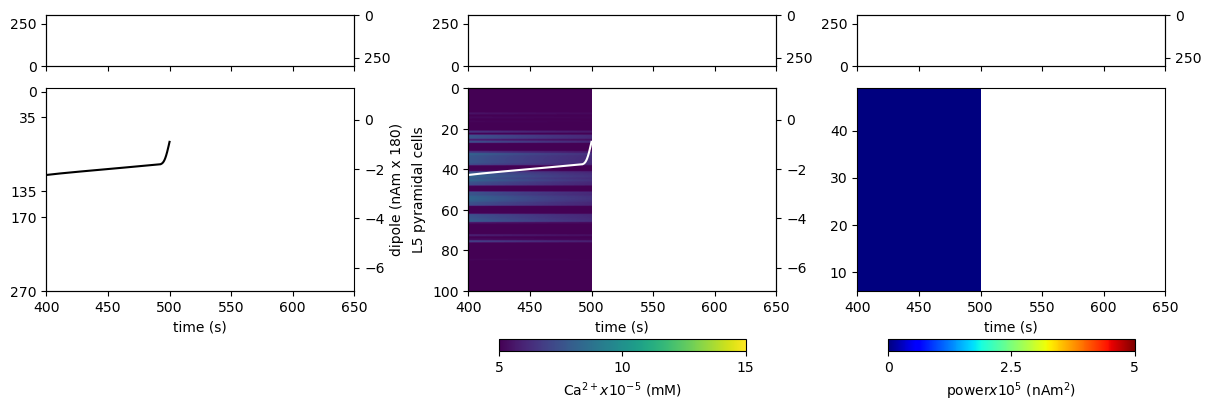

In [75]:
fig, ax = plt.subplots(2, 3, figsize=(12, 4), constrained_layout=True, height_ratios=[0.25, 1], sharex=True)

# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

for i in range(3):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 300])

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 300])
    ax1tw.invert_yaxis()

# spiking
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 

colors = [assign_color(net, gid) for gid in gids]

ax[1,0].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1,0].invert_yaxis()
ax[1,0].set_yticks([0, 35, 135, 170, 270])
axtw10 = ax[1, 0].twinx()
axtw10.plot(dpl[0].times, dpl[0].data['agg'], color='k', label='calcium')
# axtw10.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='k', linestyle=':', label='block calcium')
# axtw10.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='k', linestyle='-.', label='block calcium')

axtw10.set_ylabel('dipole (nAm x {scaling_factor})'.format(scaling_factor=scaling_factor))

ax[1, 0].spines['top'].set_visible(False)
ax[1, 0].spines['right'].set_visible(False)
ax[1, 0].set_xlim([400, 650])

im = ax[1, 1].imshow(l5_ca_tuft, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
ax[1, 1].set_ylabel('L5 pyramidal cells')
cb = plt.colorbar(im, ax=ax[1,1],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel('Ca$^{2+}x10^{-5}$ (mM)')
cb.set_ticks([5e-5, 10e-5, 15e-5])
cb.ax.set_xticklabels(['5', '10', '15'])

axtw11 = ax[1, 1].twinx()
axtw11.plot(dpl[0].times, dpl[0].data['agg'], color='w', label='calcium')
# axtw11.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='w',label='block calcium', linestyle=':')
# axtw11.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='w',label='block calcium', linestyle='-.')

im = ax[1,2].imshow(power[0, 0, :, :], aspect='auto', cmap='jet', extent=[dpl[0].times[0], dpl[0].times[-1], freqs[0], freqs[-1]], origin='lower', rasterized=True, vmin=0, vmax=5e5)
cb = plt.colorbar(im, ax=ax[1,2],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel(r'power$x10^5$ (nAm$^2$)')
cb.set_ticks([0, 250000, 500000])
cb.ax.set_xticklabels(['0', '2.5', '5'])
for i in range(3):
    ax[1, i].set_xlabel('time (s)')

fig.savefig(os.path.join(pathfig, f'beta_event_delay_distal_recruit_l2b.pdf'), dpi=300) 

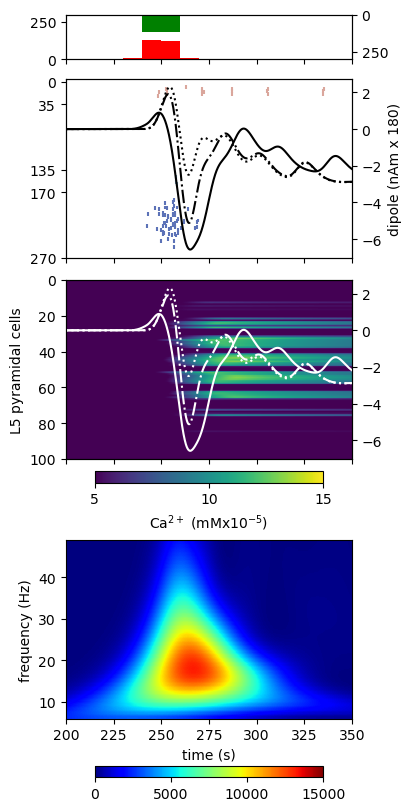

In [78]:
fig, ax = plt.subplots(4,1, figsize=(4,8), constrained_layout=True, sharex=True, height_ratios=[0.25, 1, 1, 1])

# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

ax[0].hist(spike_prox1, bins, color='r')
ax[0].set_ylim([0, 300])

ax1tw = ax[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 300])
ax1tw.invert_yaxis()

I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 

colors = [assign_color(net, gid) for gid in gids]

ax[1].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1].invert_yaxis()
ax[1].set_yticks([0, 35, 135, 170, 270])
axtw10 = ax[1].twinx()
axtw10.plot(dpl[0].times, dpl[0].data['agg'], color='k', label='calcium')
axtw10.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='k', linestyle=':', label='block calcium')
axtw10.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='k', linestyle='-.', label='block calcium')

axtw10.set_ylabel('dipole (nAm x {scaling_factor})'.format(scaling_factor=scaling_factor))

ax[1].set_xlim([400, 650])

im = ax[2].imshow(l5_ca_tuft, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
ax[2].set_ylabel('L5 pyramidal cells')
cb = plt.colorbar(im, ax=ax[2],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel('Ca$^{2+}$ (mMx10$^{-5}$)')
cb.set_ticks([5e-5, 10e-5, 15e-5])
cb.ax.set_xticklabels(['5', '10', '15'])

axtw11 = ax[2].twinx()
axtw11.plot(dpl[0].times, dpl[0].data['agg'], color='w', label='calcium')
axtw11.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='w',label='block calcium', linestyle=':')
axtw11.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='w',label='calcium 60 percent', linestyle='-.')

im = ax[3].imshow(power[0, 0, :, :], aspect='auto', cmap='jet', extent=[dpl[0].times[0], dpl[0].times[-1], freqs[0], freqs[-1]], origin='lower', rasterized=True, vmin=0, vmax=15e3)
ax[3].set_ylabel('frequency (Hz)')
cb = plt.colorbar(im, ax=ax[3],  shrink=0.8, orientation='horizontal', pad=0.02)
# cb.ax.set_xlabel(r'power (nAm$^2$ x 10$^{5}$)')

ax[3].set_xlabel('time (s)')
# cb.ax.set_xticklabels([0, 5, 10, 15])
ax[3].set_xlabel('time (s)')
ax[3].set_xlim([200, 350])
ax[3].set_xticks(np.arange(200, 351, 25))
fig.savefig(os.path.join(pathfig, 'coincidence_beta_column.pdf'), dpi=300) 

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_58081/2496013825.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cb.ax.set_xticklabels([0, 5, 10, 15])


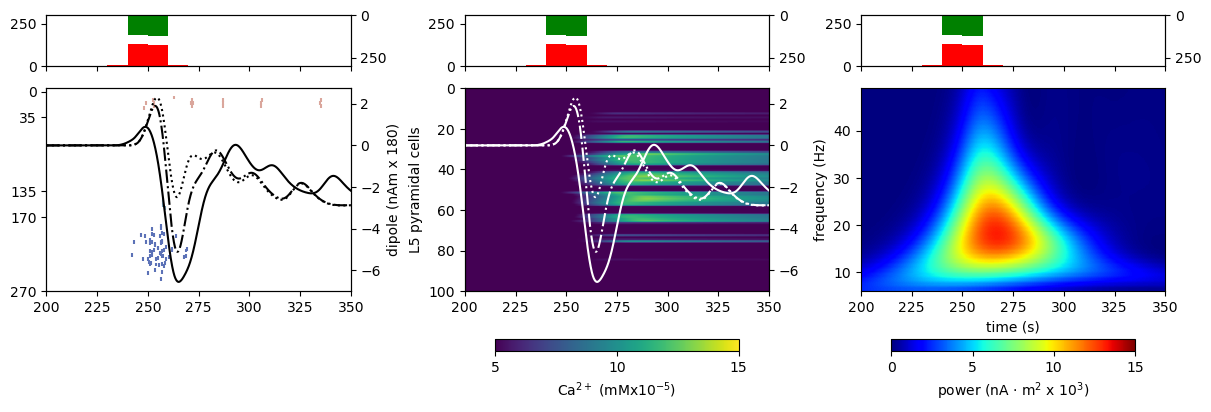

In [91]:
fig, ax = plt.subplots(2, 3, figsize=(12,4), constrained_layout=True, sharex=True, height_ratios=[0.25, 1])

# proximal and distal histogram
spike_prox1 = np.array(net.cell_response.spike_times_by_type['evprox1']).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['evdist']).reshape(-1,1)

for i in range(3):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 300])

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 300])
    ax1tw.invert_yaxis()

I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids[0]).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times[0]).reshape(-1,)[I] 

colors = [assign_color(net, gid) for gid in gids]

ax[1,0].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1,0].invert_yaxis()
ax[1,0].set_yticks([0, 35, 135, 170, 270])
axtw10 = ax[1,0].twinx()
axtw10.plot(dpl[0].times, dpl[0].data['agg'], color='k', label='calcium')
axtw10.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='k', linestyle=':', label='block calcium')
axtw10.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='k', linestyle='-.', label='block calcium')

axtw10.set_ylabel('dipole (nAm x {scaling_factor})'.format(scaling_factor=scaling_factor))

ax[1,0].set_xlim([400, 650])

im = ax[1,1].imshow(l5_ca_tuft, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
ax[1,1].set_ylabel('L5 pyramidal cells')
cb = plt.colorbar(im, ax=ax[1,1],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel('Ca$^{2+}$ (mMx10$^{-5}$)')
cb.set_ticks([5e-5, 10e-5, 15e-5])
cb.ax.set_xticklabels(['5', '10', '15'])

axtw11 = ax[1,1].twinx()
axtw11.plot(dpl[0].times, dpl[0].data['agg'], color='w', label='calcium')
axtw11.plot(dpl[0].times, dpl_no_ca[0].data['agg'], color='w',label='block calcium', linestyle=':')
axtw11.plot(dpl[0].times, dpl_60perc_ca[0].data['agg'], color='w',label='calcium 60 percent', linestyle='-.')

im = ax[1,2].imshow(power[0, 0, :, :], aspect='auto', cmap='jet', extent=[dpl[0].times[0], dpl[0].times[-1], freqs[0], freqs[-1]], origin='lower', rasterized=True, vmin=0, vmax=15e3)
ax[1,2].set_ylabel('frequency (Hz)')
cb = plt.colorbar(im, ax=ax[1,2],  shrink=0.8, orientation='horizontal', pad=0.02)
cb.ax.set_xlabel(r'power (nA $\cdot$ m$^2$ x 10$^{3}$)')
cb.ax.set_xticklabels([0, 5, 10, 15])
ax[1,2].set_xlabel('time (s)')
# cb.ax.set_xticklabels([0, 5, 10, 15])
ax[1,2].set_xlabel('time (s)')
ax[1,2].set_xlim([200, 350])
ax[1,2].set_xticks(np.arange(200, 351, 25))
fig.savefig(os.path.join(pathfig, 'coincidence_beta_landscape.pdf'), dpi=300) 

In [92]:
net.cell_types['L5_pyramidal']['cell_object'].sections

{'apical_trunk': L=102.0, diam=10.2, cm=1, Ra=100, v=-71.50652549683365,
 'apical_1': L=680.0, diam=7.48, cm=1, Ra=100, v=-70.3781183764456,
 'apical_2': L=680.0, diam=4.93, cm=1, Ra=100, v=-66.1535511211922,
 'apical_tuft': L=425.0, diam=3.4, cm=1, Ra=100, v=-61.47225400606895,
 'basal_1': L=85.0, diam=6.8, cm=1, Ra=100, v=-71.65128168943417,
 'basal_2': L=255.0, diam=8.5, cm=1, Ra=100, v=-71.77924562640379,
 'basal_3': L=255.0, diam=8.5, cm=1, Ra=100, v=-71.77924562640379,
 'apical_oblique': L=255.0, diam=5.1, cm=1, Ra=100, v=-71.53636973768913,
 'soma': L=39.0, diam=28.9, cm=1, Ra=100, v=-71.56521022702259}

In [93]:
net.cell_types['L2_pyramidal']['cell_object'].sections

{'soma': L=22.1, diam=23.4, cm=1.5, Ra=200.0, v=-73.91534035708573,
 'apical_trunk': L=59.5, diam=4.25, cm=1.5, Ra=200.0, v=-73.88877758950657,
 'apical_oblique': L=340.0, diam=3.91, cm=1.5, Ra=200.0, v=-73.91421209292815,
 'apical_1': L=306.0, diam=4.08, cm=1.5, Ra=200.0, v=-73.64560269252748,
 'apical_tuft': L=238.0, diam=3.4, cm=1.5, Ra=200.0, v=-73.27793049058045,
 'basal_1': L=85.0, diam=4.25, cm=1.5, Ra=200.0, v=-73.93352687563383,
 'basal_2': L=255.0, diam=2.72, cm=1.5, Ra=200.0, v=-73.98646383934111,
 'basal_3': L=255.0, diam=2.72, cm=1.5, Ra=200.0, v=-73.98646383934111}

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


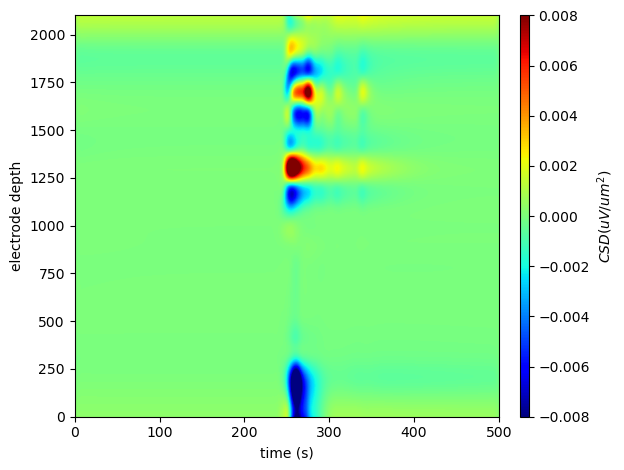

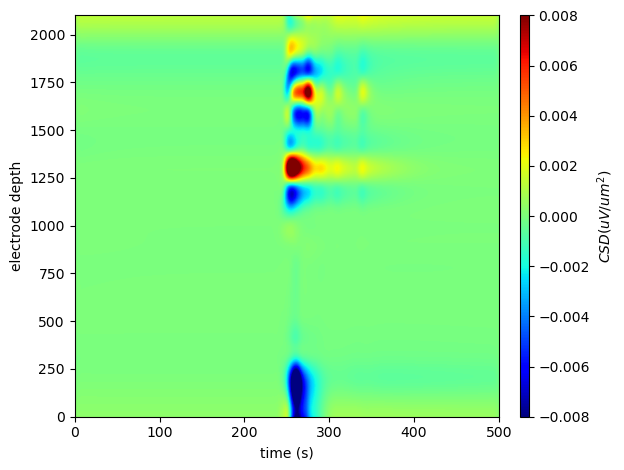

In [77]:
net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(show=False, vmin=-0.008, vmax=0.008, sink='b')


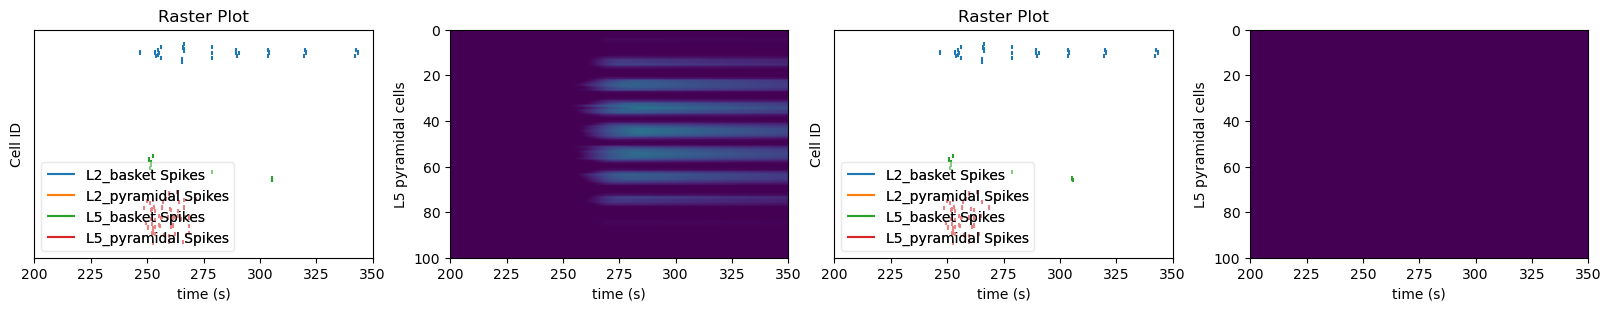

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3), constrained_layout=True, sharex=True)
net_60perc_ca.cell_response.plot_spikes_raster(ax=ax[0], show=False)
im = ax[1].imshow(l5_ca_tuft_60perc, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)
ax[1].set_ylabel('L5 pyramidal cells')

net_no_ca.cell_response.plot_spikes_raster(ax=ax[2], show=False)
im = ax[3].imshow(l5_ca_tuft_noca, aspect='auto', cmap='viridis', extent=[dpl[0].times[0], dpl[0].times[-1], 100, 0], rasterized=True, vmin=5e-5, vmax=15e-5)


for i in range(4):
    ax[i].set_xlabel('time (s)')
    ax[i].set_xlim([200, 350])
    ax[i].set_xticks(np.arange(200, 351, 25))
    
ax[3].set_ylabel('L5 pyramidal cells')
fig.savefig(os.path.join(pathfig, 'duecker_2025_ET_coincidence_beta_reduce_ca_spike_change.pdf'), dpi=300) 


